# Do Vulnerability Detectors Learn the Bug or the Names?
**TF-IDF with Random Forest versus fine-tuned CodeBERT on C functions**

ARTI 404 Natural Language Processing · IAU (CCSIT) · Section 9MA2 · Group 1
Khalid Waleed Alhilal (leader) · Ali Khalid Albinali · Mishary Waleed AlAwadh

**Question.** Which method detects vulnerable C functions more reliably, and which one loses less accuracy
and macro F1 when identifier names are replaced?

**Input / output.** One C function as text → `Vulnerable` or `Safe` and the probability of `Vulnerable`.

## 1. Setup
Environment: Jupyter (local), Python 3.11, CUDA 12.8, NVIDIA RTX 5080.

* `RUN_FULL_TRAINING = False` (default): loads the saved models (downloaded from the GitHub Release if they
  are missing) and the saved results, then recomputes the seed-42 test metrics from the loaded models and
  checks that they equal `results/metrics_summary.json`.
* `RUN_FULL_TRAINING = True`: reruns every experiment with `scripts/run_experiments.py`
  (about 3 hours on an RTX 5080).

In [1]:
RUN_FULL_TRAINING = False

import json
import platform
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

import warnings
warnings.filterwarnings("ignore")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()      # keep the notebook output readable
hf_logging.disable_progress_bar()

REPO = Path.cwd()
assert (REPO / "src").is_dir(), "Start Jupyter in the repository root folder."
sys.path.insert(0, str(REPO))
RESULTS = REPO / "results"
pd.set_option("display.max_colwidth", 80)


def run(*args: str) -> None:
    """Run one step of scripts/run_experiments.py and show its output."""
    cmd = [sys.executable, "scripts/run_experiments.py", *args]
    print("$ python", " ".join(cmd[1:]))
    subprocess.run(cmd, check=True, cwd=REPO)


def load_json(name: str) -> dict:
    with open(RESULTS / name, encoding="utf-8") as fh:
        return json.load(fh)

In [2]:
# Package versions used for the reported results
import importlib.metadata as md
import torch

print(f"Python {platform.python_version()} | torch {torch.__version__} | CUDA {torch.version.cuda} | "
      f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU)'}")
for pkg in ["transformers", "datasets", "scikit-learn", "pandas", "numpy", "tree-sitter", "tree-sitter-c",
            "scipy", "matplotlib", "joblib"]:
    print(f"  {pkg:<13} {md.version(pkg)}")

Python 3.11.18 | torch 2.11.0+cu128 | CUDA 12.8 | GPU: NVIDIA GeForce RTX 5080
  transformers  5.24.1
  datasets      5.2.0
  scikit-learn  1.9.1
  pandas        3.1.1
  numpy         2.4.6
  tree-sitter   0.27.0
  tree-sitter-c 0.24.2
  scipy         1.17.1
  matplotlib    3.11.2
  joblib        1.6.0


In [3]:
# Saved models: download from the GitHub Release if they are not in models/ yet
if not RUN_FULL_TRAINING:
    from src.assets import ensure_models
    ensure_models()

found   models\codebert_seed42
found   models\tfidf_rf_seed42.joblib


## 2. Data
CodeXGLUE Defect Detection (Devign): C functions from FFmpeg and QEMU, label 1 = vulnerable.
`data_prep.py` removes comments and extra whitespace and hashes every function, so that copies of the same
function stay in one split only (no test function is seen in training). Functions whose copies carry
different labels are removed.

In [4]:
from src import data_prep

if RUN_FULL_TRAINING or not (REPO / "data" / "processed" / "test_renamed.parquet").exists():
    run("download")   # Hugging Face -> data/raw/
    run("clean")      # data_prep.py -> data/processed/{train,dev,test}.parquet + results/data_stats.json
    run("rename")     # renaming.py  -> test_renamed.parquet, train_augmented.parquet
    run("rename-extra")  # word-name scheme, variables-only and function-names-only test sets

splits = data_prep.load_splits("data/processed", names=("train", "dev", "test", "test_renamed"))
stats = load_json("data_stats.json")

counts = pd.DataFrame(stats["after_cleaning"]).T
counts.insert(0, "official", pd.Series(stats["official"]))
display(counts)
print("Duplicates:", stats["duplicates"])
t = stats["test_truncated_512"]
print(f"Test functions longer than 512 CodeBERT tokens: {t['count']} ({100 * t['pct']:.2f}%)")

,official,n,vulnerable,safe
train,21854,21713,9946,11767
dev,2732,2723,1184,1539
test,2732,2717,1246,1471


Duplicates: {'within_split_removed': 1, 'cross_split_removed': 2, 'label_conflict_groups': 81, 'label_conflict_rows_removed': 162}
Test functions longer than 512 CodeBERT tokens: 873 (32.13%)


In [5]:
# One cleaned training example
row = splits["train"].iloc[0]
print("label:", row["label"], "(1 = vulnerable)")
print(row["code"][:600])

label: 0 (1 = vulnerable)
static av_cold int vdadec_init(AVCodecContext *avctx) { VDADecoderContext *ctx = avctx->priv_data; struct vda_context *vda_ctx = &ctx->vda_ctx; OSStatus status; int ret; ctx->h264_initialized = 0; if (!ff_h264_vda_decoder.pix_fmts) { if (kCFCoreFoundationVersionNumber < kCFCoreFoundationVersionNumber10_7) ff_h264_vda_decoder.pix_fmts = vda_pixfmts_prior_10_7; else ff_h264_vda_decoder.pix_fmts = vda_pixfmts; } memset(vda_ctx, 0, sizeof(struct vda_context)); vda_ctx->width = avctx->width; vda_ctx->height = avctx->height; vda_ctx->format = 'avc1'; vda_ctx->use_sync_decoding = 1; vda_ctx->use_ref_


### Renamed test set
`renaming.py` parses each function with tree-sitter and replaces user-defined names consistently:
the function's own name and called project functions become `FUN1, FUN2, …`, all other identifiers
`VAR1, VAR2, …`. Keywords, C library calls, struct fields, type names and ALL_CAPS macros are kept, so the
program does the same thing and the label stays valid.

In [6]:
ren = load_json("renaming_stats.json")
display(pd.Series(ren, name="value").to_frame())

i = splits["test"].index[0]
print("BEFORE:\n", splits["test"].loc[i, "code"][:500])
print("\nAFTER:\n", splits["test_renamed"].loc[i, "code"][:500])

,value
test_functions_changed_pct,1.0
mean_identifiers_renamed,14.83
mean_var_renamed,9.17
mean_fun_renamed,5.67
new_parse_errors,2
new_parse_errors_ids,"[6098, 25119]"
words_scheme,"{'test_functions_changed_pct': 1.0, 'mean_identifiers_renamed': 14.83, 'mean..."
var_only,"{'test_functions_changed_pct': 0.9952, 'mean_identifiers_renamed': 9.17, 'me..."
fun_only,"{'test_functions_changed_pct': 0.961, 'mean_identifiers_renamed': 5.67, 'mea..."


BEFORE:
 int ff_get_wav_header(AVFormatContext *s, AVIOContext *pb, AVCodecContext *codec, int size, int big_endian) { int id; uint64_t bitrate; if (size < 14) { avpriv_request_sample(codec, "wav header size < 14"); return AVERROR_INVALIDDATA; } codec->codec_type = AVMEDIA_TYPE_AUDIO; if (!big_endian) { id = avio_rl16(pb); if (id != 0x0165) { codec->channels = avio_rl16(pb); codec->sample_rate = avio_rl32(pb); bitrate = avio_rl32(pb) * 8LL; codec->block_align = avio_rl16(pb); } } else { id = avio_rb16(pb

AFTER:
 int FUN1(AVFormatContext *VAR1, AVIOContext *VAR2, AVCodecContext *VAR3, int VAR4, int VAR5) { int VAR6; uint64_t VAR7; if (VAR4 < 14) { FUN2(VAR3, "wav header size < 14"); return AVERROR_INVALIDDATA; } VAR3->codec_type = AVMEDIA_TYPE_AUDIO; if (!VAR5) { VAR6 = FUN3(VAR2); if (VAR6 != 0x0165) { VAR3->channels = FUN3(VAR2); VAR3->sample_rate = FUN4(VAR2); VAR7 = FUN4(VAR2) * 8LL; VAR3->block_align = FUN3(VAR2); } } else { VAR6 = FUN5(VAR2); VAR3->channels = FUN5(VAR2); VAR3->sa

## 3. Method 1 — TF-IDF + Random Forest
`c_tokenizer.py` keeps multi-character operators whole, replaces string and char literals with `<STR>` /
`<CHR>`, and adds the lower-cased parts of every identifier (`dstBuf` → `dstBuf`, `dst`, `buf`).
TF-IDF on unigrams + bigrams feeds a Random Forest. All hyper-parameters are chosen on dev macro F1
(seed 42); the test sets are never used for tuning.

In [7]:
from src.c_tokenizer import tokenize_c

print(tokenize_c("if (len > n) memcpy(dstBuf, src_ptr, len);"))

['if', '(', 'len', '>', 'n', ')', 'memcpy', '(', 'dstBuf', 'dst', 'buf', ',', 'src_ptr', 'src', 'ptr', ',', 'len', ')', ';']


In [8]:
if RUN_FULL_TRAINING:
    run("tfidf-tune")         # 64 settings on dev
    run("tfidf-seeds")        # seeds 42, 123, 2026 with the best settings
    run("length-baseline")    # diagnostic: function length only

grid = pd.read_csv(RESULTS / "tfidf_grid.csv")
print("Best settings (dev macro F1):", load_json("tfidf_best_params.json")["best_params"])
display(grid.head(5))

Best settings (dev macro F1): {'ngram_range': [1, 1], 'max_features': 50000, 'n_estimators': 300, 'max_depth': 60, 'min_samples_leaf': 2, 'class_weight': 'balanced'}


,ngram_range,max_features,n_estimators,max_depth,min_samples_leaf,class_weight,dev_macro_f1,dev_accuracy,dev_vuln_recall,fit_seconds
0,"(1, 1)",50000,300,60.0,2,balanced,0.616347,0.620639,0.592061,1.2
1,"(1, 2)",20000,500,60.0,2,balanced,0.611259,0.616232,0.578547,4.5
2,"(1, 1)",20000,300,NaN,1,balanced,0.610849,0.616599,0.569257,4.2
3,"(1, 1)",20000,500,NaN,2,balanced,0.610366,0.614029,0.594595,3.7
4,"(1, 1)",50000,500,60.0,2,balanced,0.610157,0.614763,0.581926,1.9


In [9]:
# Top 30 features of the seed-42 model, with their kind
display(pd.read_csv(RESULTS / "tfidf_top_features.csv"))

,feature,importance,kind
0,},0.014776,punctuation
1,=,0.005826,punctuation
2,target_phys_addr_t,0.005330,project-specific
3,;,0.004358,punctuation
4,phys,0.004345,identifier part
5,0,0.004345,number
6,",",0.004250,punctuation
7,+,0.004224,punctuation
8,return,0.004206,keyword
9,),0.004044,punctuation


## 4. Method 2 — fine-tuned CodeBERT
`microsoft/codebert-base` (125M parameters) + a classification head. Each function is cut to 512 sub-word
tokens. AdamW with a linear schedule and 10% warm-up, weight decay 0.01, effective batch 32, bf16.
The learning rate is chosen from {1e-5, 2e-5, 3e-5} on dev macro F1 (seed 42), and the best epoch is
kept with early stopping (patience 2).

In [10]:
if RUN_FULL_TRAINING:
    run("codebert-lr-search")   # seed 42, three learning rates
    run("codebert-seeds")       # seeds 123 and 2026 with the chosen learning rate

display(pd.read_csv(RESULTS / "codebert_lr_search.csv"))
print("Chosen:", load_json("codebert_best_params.json"))

with open(REPO / "models" / "codebert_seed42" / "train_log.json", encoding="utf-8") as fh:
    log = json.load(fh)
display(pd.DataFrame(log["history"]))

,lr,best_epoch,epochs_run,dev_accuracy,dev_macro_f1,dev_vuln_recall,total_secs,secs_per_epoch
0,0.00001,8,8,0.662137,0.636512,0.456081,1058.3,127.7
1,0.00002,6,8,0.643775,0.631191,0.527872,1048.2,125.2
2,0.00003,2,4,0.642674,0.634467,0.566723,518.7,125.2


Chosen: {'learning_rate': 1e-05, 'best_epoch': 8, 'dev_macro_f1': 0.6365118978525828, 'batch_size': 32, 'max_len': 512}


,epoch,train_loss,steps,train_secs,dev_secs,dev_accuracy,dev_macro_f1,dev_vuln_recall
0,1,0.685681,679,138.3,3.0,0.591994,0.468147,0.125845
1,2,0.641750,1358,129.8,3.0,0.628718,0.611200,0.478885
2,3,0.593872,2037,127.8,3.1,0.636798,0.585001,0.326014
3,4,0.547310,2716,125.6,2.7,0.646346,0.622080,0.451858
4,5,0.508256,3395,125.0,2.7,0.647815,0.596629,0.335304
5,6,0.474070,4074,125.0,2.7,0.652222,0.634599,0.497466
6,7,0.445695,4753,125.1,2.7,0.656629,0.634360,0.471284
7,8,0.425391,5432,125.1,2.7,0.662137,0.636512,0.456081


## 5. Results
Every number below is read from `results/metrics_summary.json` (mean ± std over seeds 42, 123, 2026).
Drop = original test − renamed test.

In [11]:
if RUN_FULL_TRAINING:
    run("augment", "--method", "tfidf_rf", "--seeds", "42", "123", "2026")   # original + renamed copies
    run("augment", "--method", "codebert", "--seeds", "42", "123", "2026")
    run("predict-missing")   # score every saved model on every test set
    run("ensemble")          # mean probability of the two methods (evaluation only)
    run("head-tail")         # CodeBERT with first 128 + last 382 tokens for long functions
    run("summarize")

summary = load_json("metrics_summary.json")


def fmt(cell):
    if cell is None:
        return ""
    return f"{100 * cell['mean']:.2f}" + ("" if cell.get("std") is None else f" ± {100 * cell['std']:.2f}")


rows = []
TEST_KEYS = [("original_test", "original test"), ("renamed_test", "renamed test (VARn/FUNn)"),
             ("renamed_words_test", "renamed test (word names)"), ("drop", "drop VARn/FUNn"), ("drop_words", "drop word names")]
for method, name in [("tfidf_rf", "TF-IDF + RF"), ("codebert", "CodeBERT"), ("length_baseline", "Length only (diagnostic)")]:
    block = summary.get(method, {})
    for key, label in TEST_KEYS:
        if key in block:
            rows.append({"method": name, "set": label,
                         **{m: fmt(block[key].get(m)) for m in ["accuracy", "macro_f1", "vuln_recall", "roc_auc"]}})
display(pd.DataFrame(rows))
print("Majority baseline (original test):", summary["majority_baseline"]["original_test"])

,method,set,accuracy,macro_f1,vuln_recall,roc_auc
0,TF-IDF + RF,original test,60.08 ± 0.50,59.89 ± 0.53,58.00 ± 1.02,65.01 ± 0.13
1,TF-IDF + RF,renamed test (VARn/FUNn),60.54 ± 0.54,59.93 ± 0.56,52.46 ± 0.80,65.74 ± 0.35
2,TF-IDF + RF,renamed test (word names),58.79 ± 0.13,58.53 ± 0.20,55.56 ± 1.30,63.37 ± 0.05
3,TF-IDF + RF,drop VARn/FUNn,-0.47 ± 1.01,-0.04 ± 1.06,,-0.73 ± 0.25
4,TF-IDF + RF,drop word names,1.29 ± 0.63,1.35 ± 0.72,,1.64 ± 0.15
5,CodeBERT,original test,63.81 ± 0.95,62.10 ± 1.33,46.58 ± 3.70,70.75 ± 0.75
6,CodeBERT,renamed test (VARn/FUNn),59.15 ± 1.76,58.55 ± 2.24,52.51 ± 7.77,62.67 ± 2.40
7,CodeBERT,renamed test (word names),59.21 ± 1.01,58.66 ± 0.30,55.32 ± 9.36,63.86 ± 1.02
8,CodeBERT,drop VARn/FUNn,4.66 ± 0.99,3.55 ± 1.00,,8.08 ± 1.66
9,CodeBERT,drop word names,4.60 ± 0.42,3.43 ± 1.24,,6.89 ± 0.68


Majority baseline (original test): {'accuracy': 0.5414, 'macro_f1': 0.3512, 'vuln_recall': 0.0, 'majority_label': 0, 'roc_auc': 0.5}


In [12]:
# McNemar's test on the paired seed-42 predictions (TF-IDF + RF vs CodeBERT)
display(pd.DataFrame(summary["mcnemar"]).T)

,b,c,statistic,p_value,method
original_test,392,470,6.8782,0.0087,chi2_cc
renamed_test,503,432,5.2406,0.0221,chi2_cc


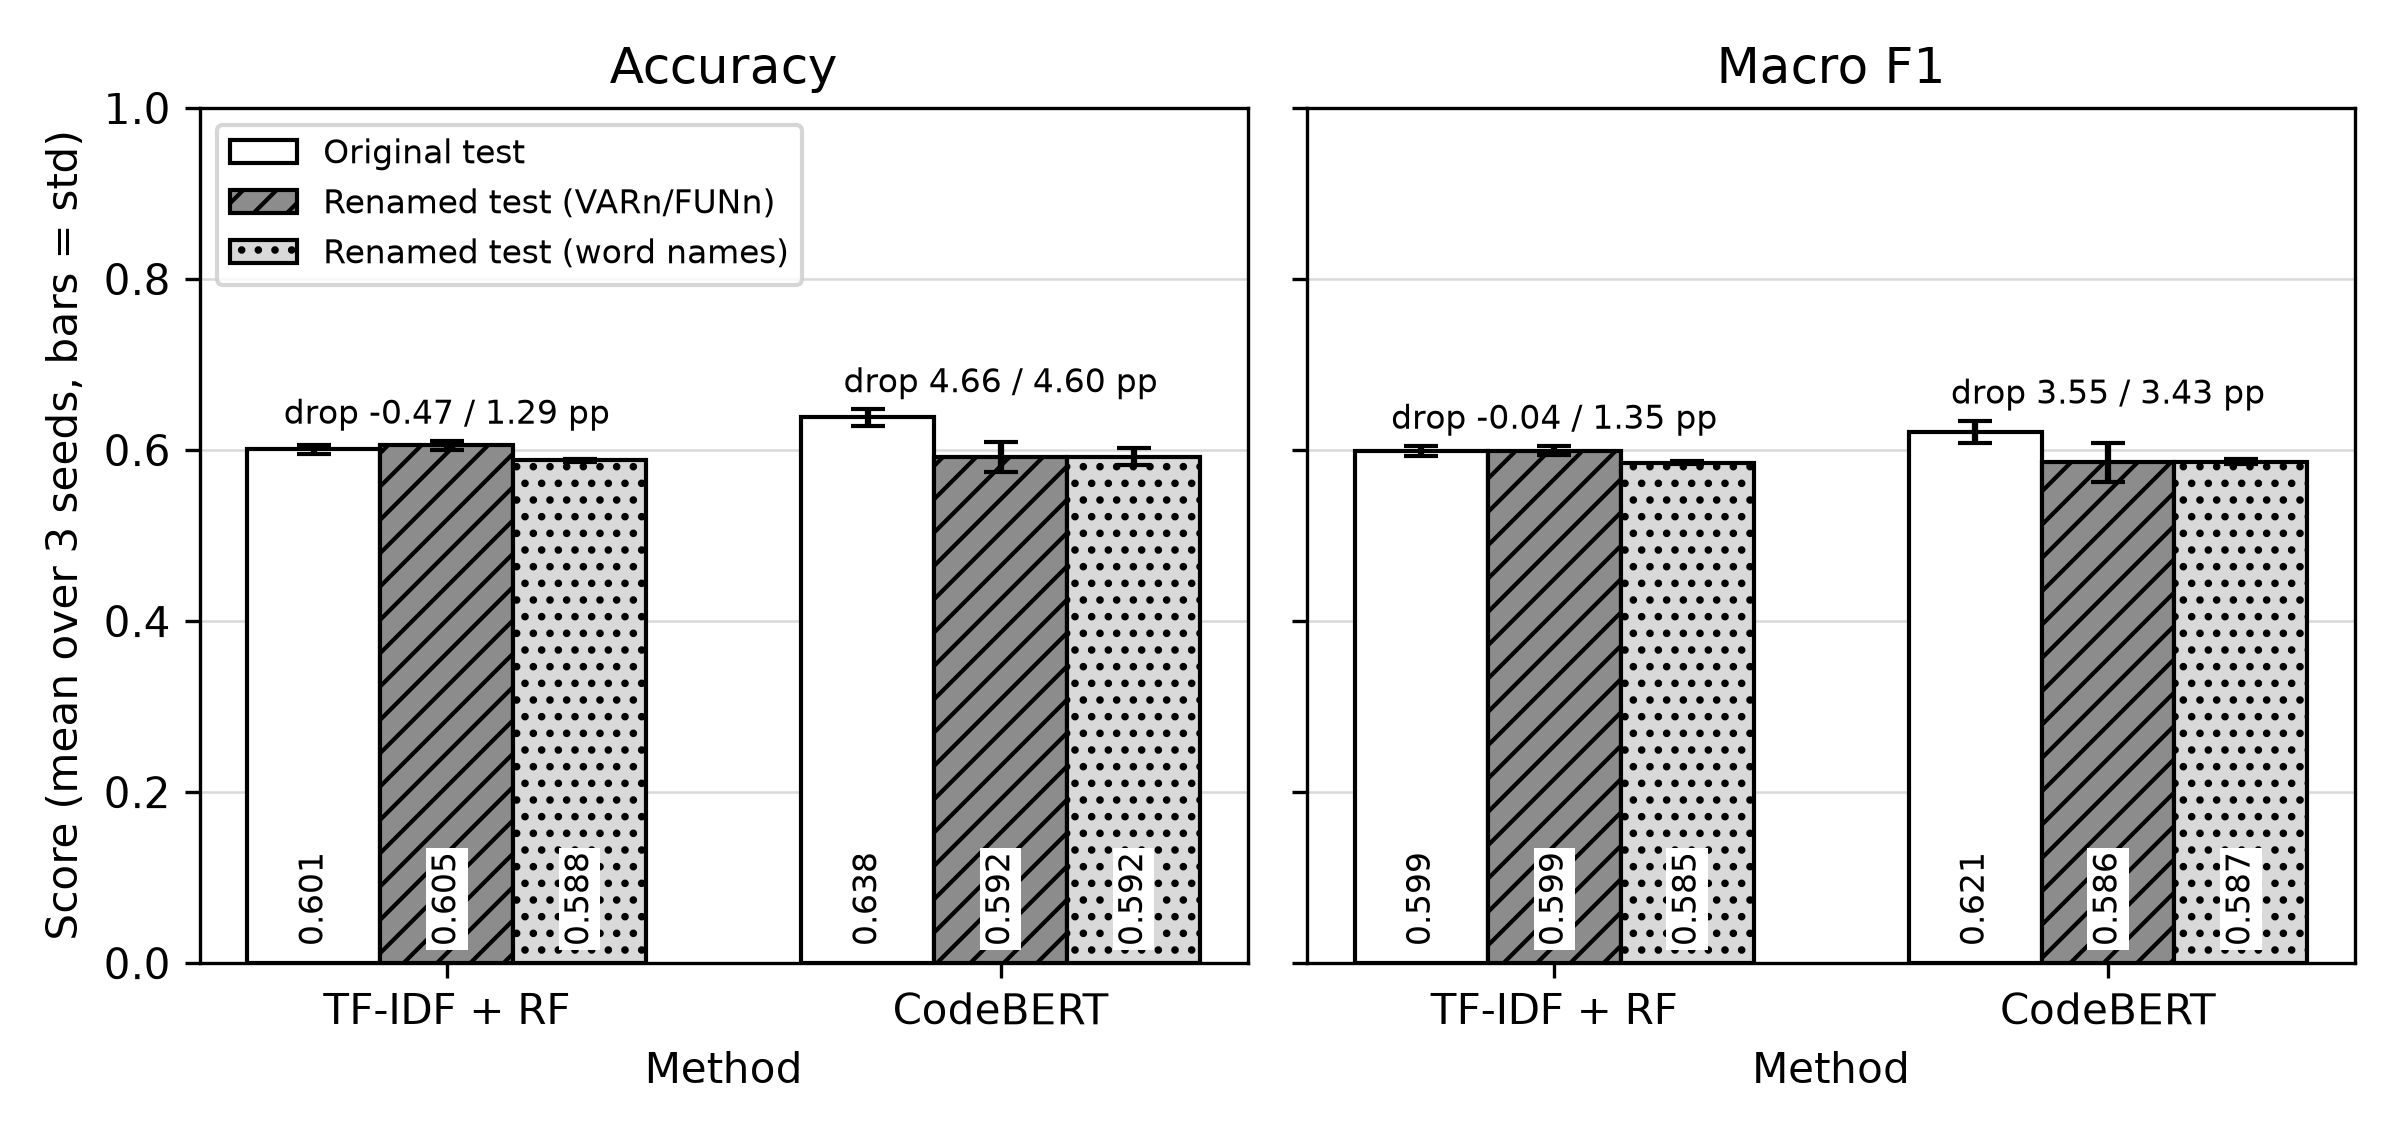

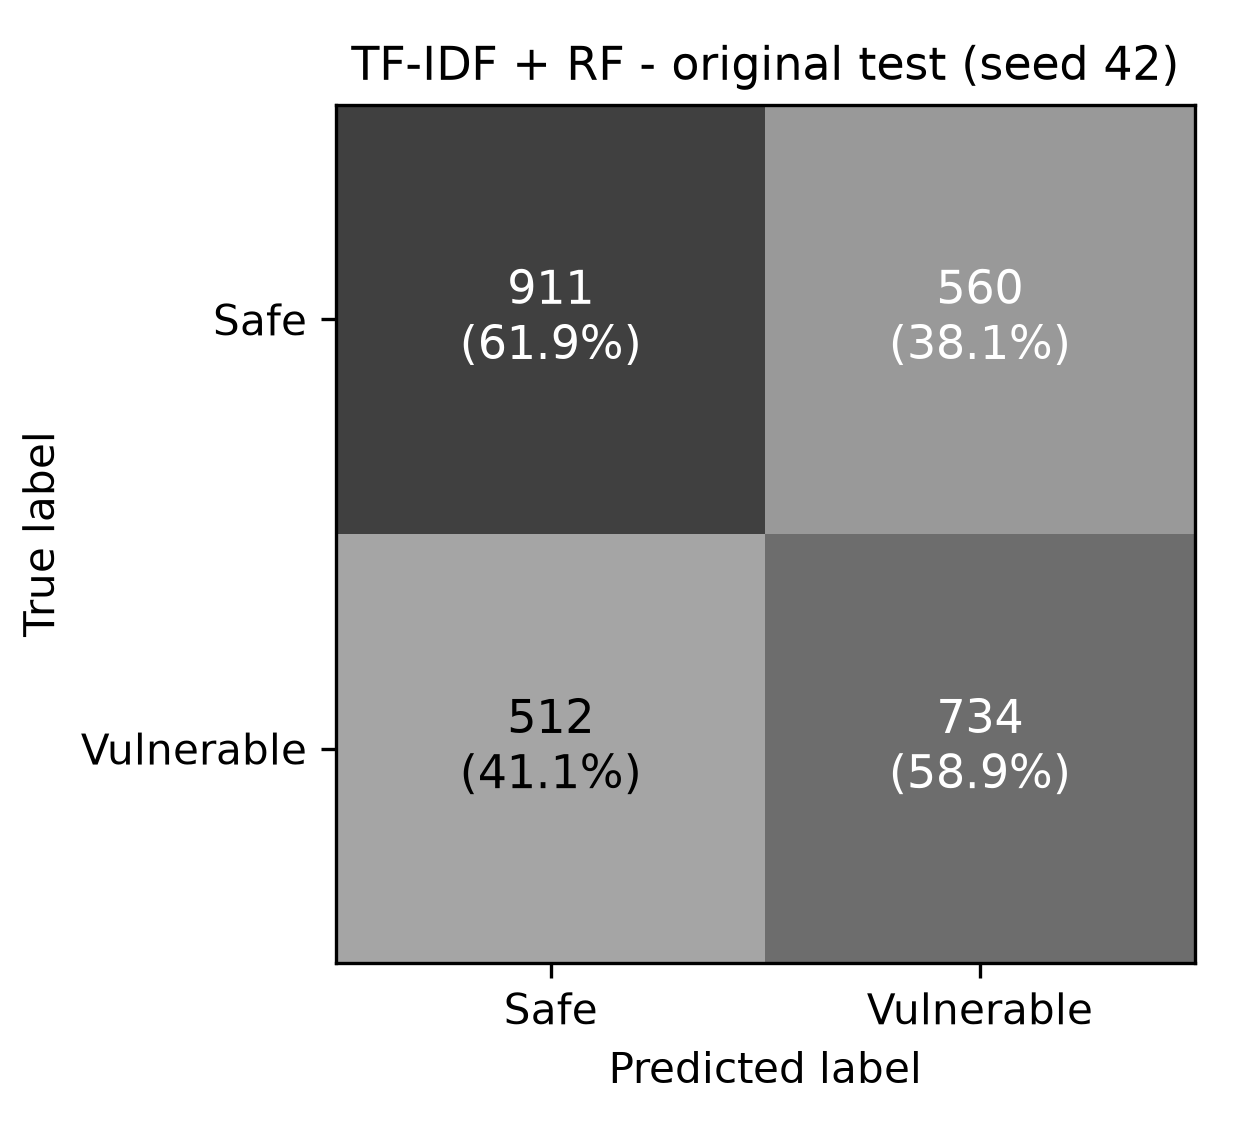

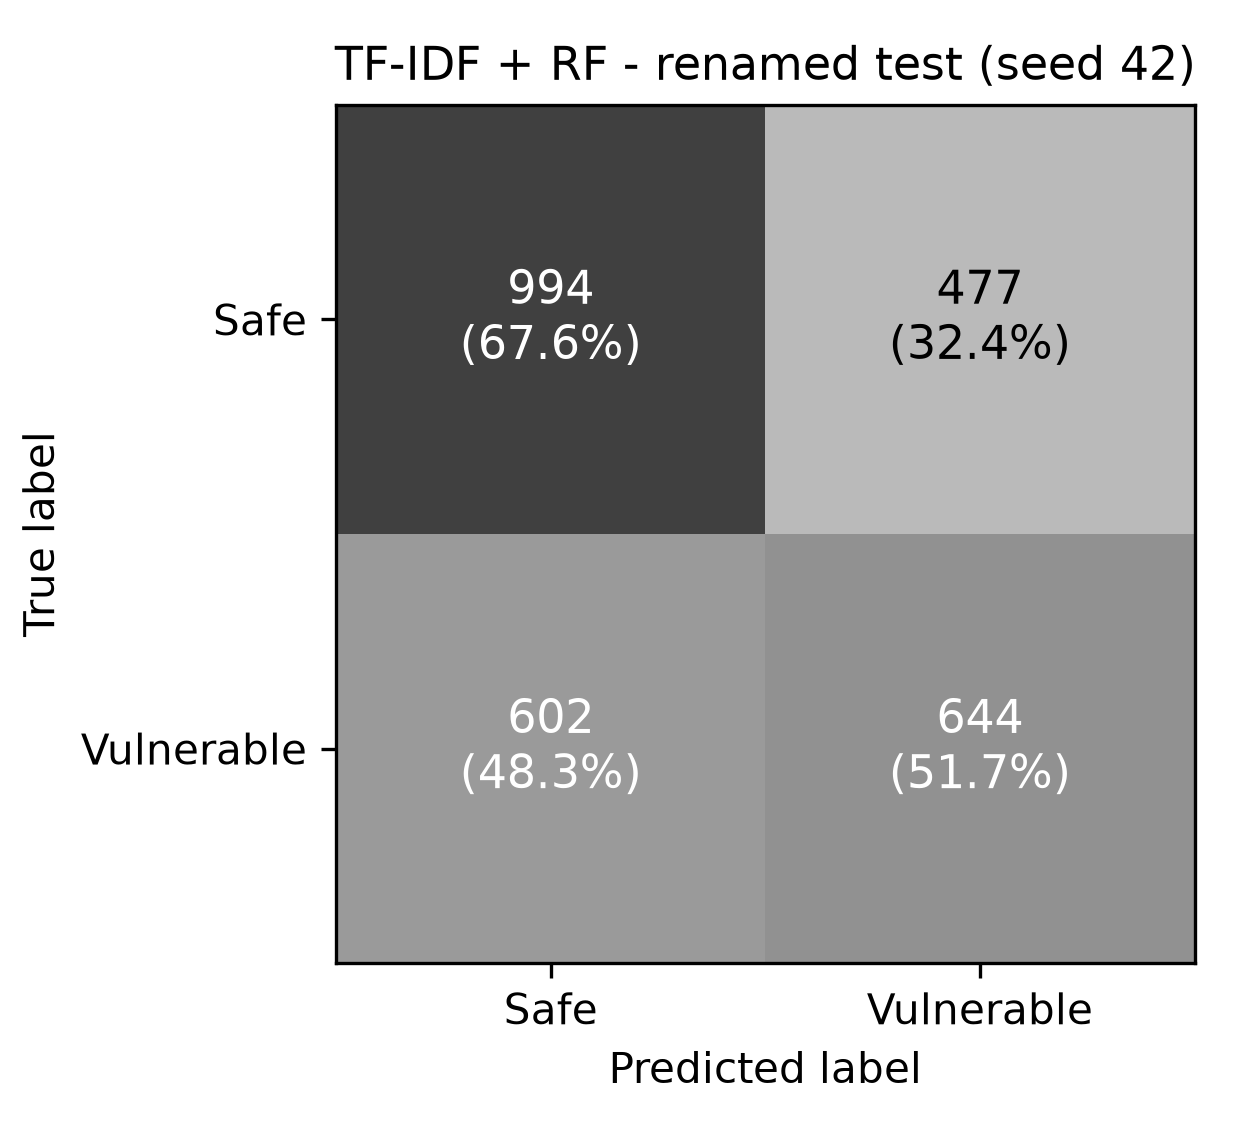

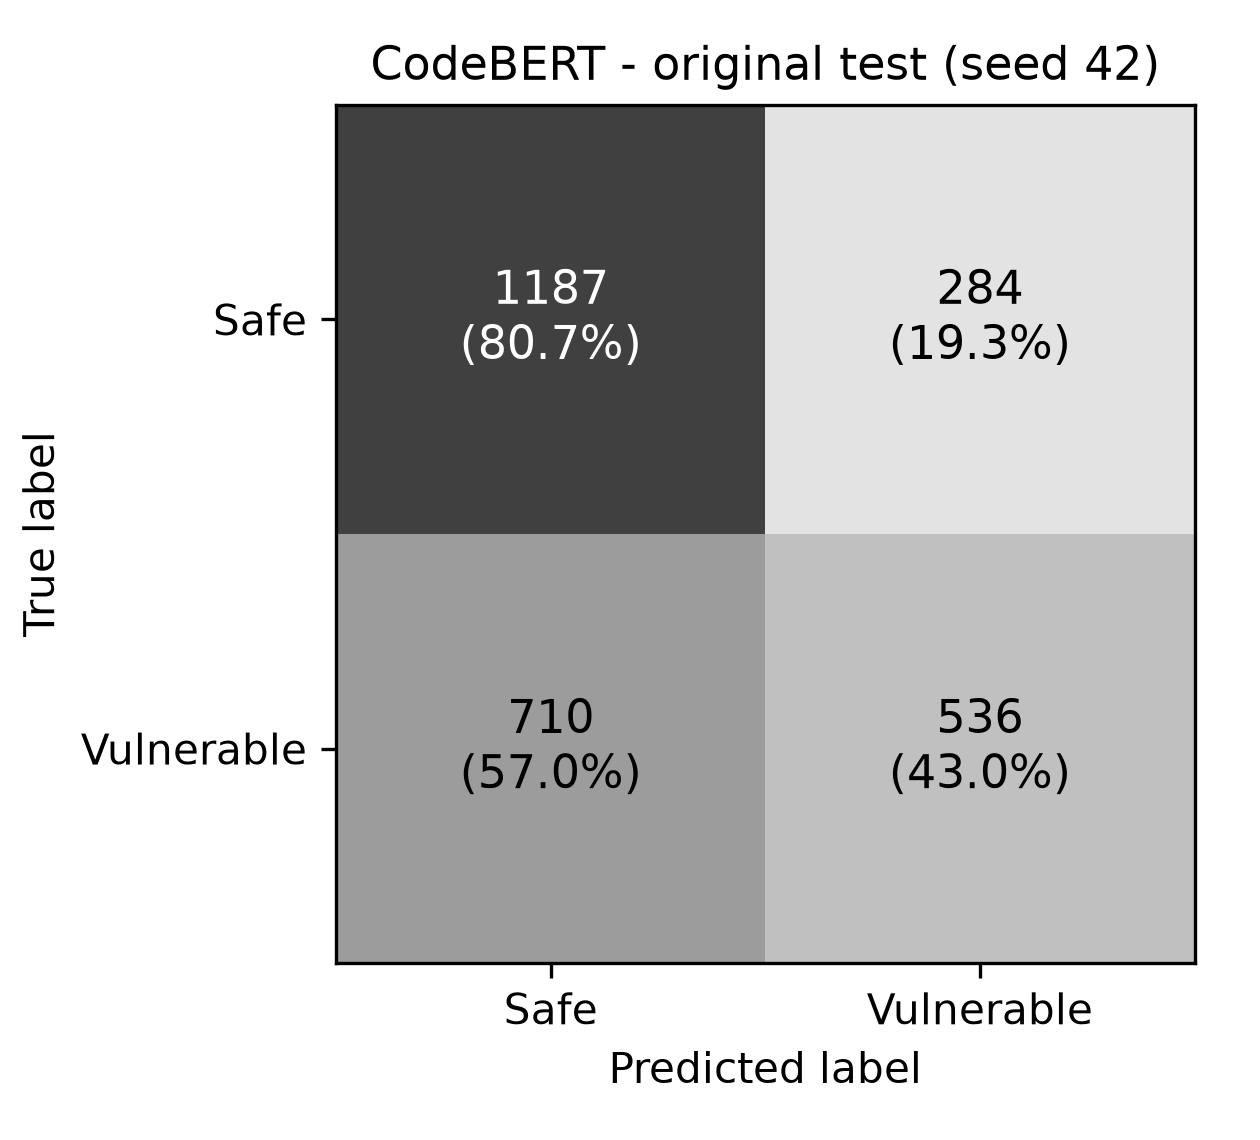

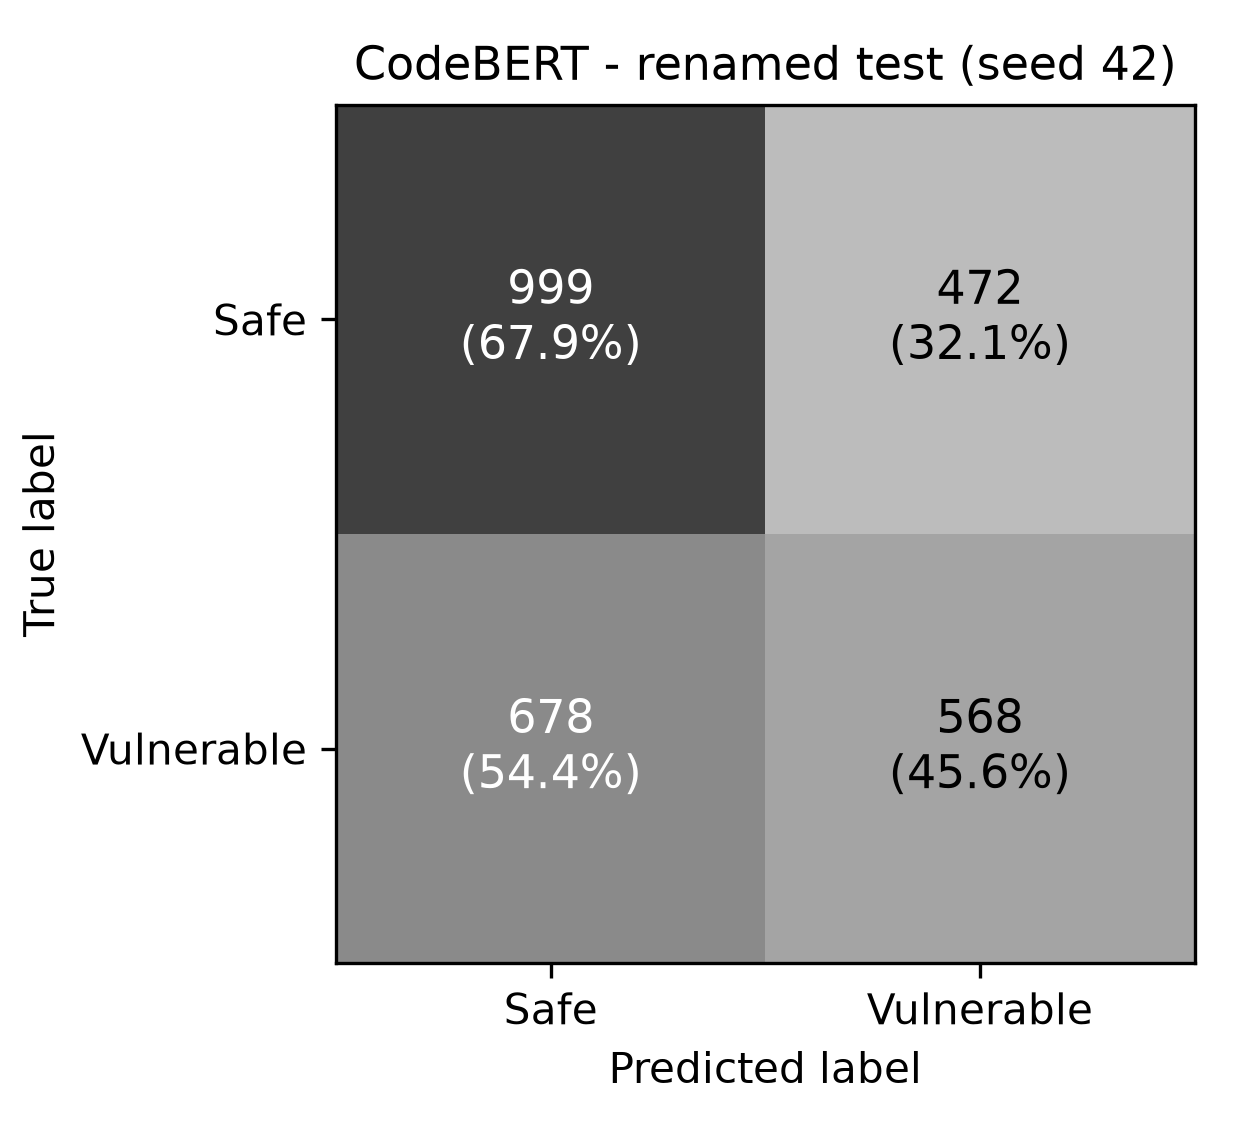

In [13]:
for f in ["drop_chart.png", "cm_tfidf_rf_orig.png", "cm_tfidf_rf_ren.png", "cm_codebert_orig.png", "cm_codebert_ren.png"]:
    path = RESULTS / "figures" / f
    if path.exists():
        display(Image(filename=str(path), width=520))

In [14]:
# Functions longer than 512 tokens (CodeBERT sees only the first 512) vs the rest, seed 42
display(pd.read_csv(RESULTS / "truncation_table.csv"))

,method,truncated,n,accuracy,macro_f1,vuln_recall
0,tfidf_rf,False,1844,0.6508,0.6430,0.5617
1,tfidf_rf,True,873,0.5097,0.5039,0.6429
2,codebert,False,1844,0.6681,0.6418,0.4431
3,codebert,True,873,0.5624,0.5489,0.4048


In [15]:
# Planned improvement: training on original + renamed copies (3 seeds)
aug = summary["augmentation"]
rows = []
for method, name in [("tfidf_rf", "TF-IDF + RF"), ("codebert", "CodeBERT"), ("ensemble", "Ensemble")]:
    for key, label in TEST_KEYS:
        if key in aug.get(method, {}):
            rows.append({"method": name + " (augmented)", "set": label,
                         **{m: fmt(aug[method][key].get(m)) for m in ["accuracy", "macro_f1", "vuln_recall", "roc_auc"]}})
display(pd.DataFrame(rows))

,method,set,accuracy,macro_f1,vuln_recall,roc_auc
0,TF-IDF + RF (augmented),original test,59.93 ± 0.51,59.73 ± 0.48,57.70 ± 0.24,64.94 ± 0.28
1,TF-IDF + RF (augmented),renamed test (VARn/FUNn),58.72 ± 0.54,58.39 ± 0.56,54.41 ± 0.89,63.16 ± 0.33
2,TF-IDF + RF (augmented),renamed test (word names),58.61 ± 0.81,58.44 ± 0.83,57.12 ± 1.56,63.42 ± 0.62
3,TF-IDF + RF (augmented),drop VARn/FUNn,1.21 ± 0.32,1.34 ± 0.31,,1.78 ± 0.05
4,TF-IDF + RF (augmented),drop word names,1.32 ± 0.64,1.29 ± 0.67,,1.52 ± 0.39
5,CodeBERT (augmented),original test,63.22 ± 0.86,62.04 ± 1.25,50.13 ± 5.06,70.35 ± 0.80
6,CodeBERT (augmented),renamed test (VARn/FUNn),63.15 ± 0.85,61.91 ± 1.99,51.15 ± 10.32,69.50 ± 1.00
7,CodeBERT (augmented),renamed test (word names),62.10 ± 0.99,61.68 ± 0.79,56.39 ± 1.82,68.17 ± 0.98
8,CodeBERT (augmented),drop VARn/FUNn,0.07 ± 1.06,0.12 ± 1.72,,0.85 ± 0.68
9,CodeBERT (augmented),drop word names,1.12 ± 0.13,0.36 ± 0.66,,2.18 ± 0.23


### Extra analyses (evaluation only, no new training)
* **Partial renaming:** only variables (`VARn`) or only function names (`FUNn`) are replaced.
* **Ensemble:** mean of P(vulnerable) from TF-IDF + RF and CodeBERT (same seed), threshold 0.5.
* **Head + tail:** CodeBERT reads the first 128 and the last 382 tokens of functions longer than 512 tokens.

In [16]:
rows = []
for method, name in [("tfidf_rf", "TF-IDF + RF"), ("codebert", "CodeBERT"), ("ensemble", "Ensemble")]:
    block = summary[method]
    for key, label in [("drop", "all names"), ("drop_var_only", "variables only"), ("drop_fun_only", "function names only")]:
        rows.append({"method": name, "renamed": label, **{m: fmt(block[key].get(m)) for m in ["accuracy", "macro_f1", "roc_auc"]}})
print("Drop (original - renamed), percentage points")
display(pd.DataFrame(rows))

Drop (original - renamed), percentage points


,method,renamed,accuracy,macro_f1,roc_auc
0,TF-IDF + RF,all names,-0.47 ± 1.01,-0.04 ± 1.06,-0.73 ± 0.25
1,TF-IDF + RF,variables only,-1.37 ± 0.54,-1.35 ± 0.58,-1.64 ± 0.22
2,TF-IDF + RF,function names only,-0.17 ± 0.38,0.16 ± 0.43,0.00 ± 0.11
3,CodeBERT,all names,4.66 ± 0.99,3.55 ± 1.00,8.08 ± 1.66
4,CodeBERT,variables only,1.53 ± 0.47,0.10 ± 0.37,2.35 ± 0.51
5,CodeBERT,function names only,1.91 ± 0.31,2.54 ± 1.11,3.80 ± 1.15
6,Ensemble,all names,3.83 ± 1.04,3.13 ± 1.09,5.97 ± 1.32
7,Ensemble,variables only,0.72 ± 0.73,-0.31 ± 0.51,1.10 ± 0.31
8,Ensemble,function names only,1.50 ± 0.52,2.10 ± 1.12,2.73 ± 0.85


In [17]:
rows = []
for method, name in [("codebert", "CodeBERT"), ("ensemble", "Ensemble")]:
    for key, label in TEST_KEYS[:3]:
        rows.append({"model": name, "set": label, **{m: fmt(summary[method][key].get(m)) for m in ["accuracy", "macro_f1", "vuln_recall"]}})
display(pd.DataFrame(rows))
print("McNemar ensemble vs CodeBERT (seed 42):")
display(pd.DataFrame(summary["mcnemar_ensemble_vs_codebert"]).T)

,model,set,accuracy,macro_f1,vuln_recall
0,CodeBERT,original test,63.81 ± 0.95,62.10 ± 1.33,46.58 ± 3.70
1,CodeBERT,renamed test (VARn/FUNn),59.15 ± 1.76,58.55 ± 2.24,52.51 ± 7.77
2,CodeBERT,renamed test (word names),59.21 ± 1.01,58.66 ± 0.30,55.32 ± 9.36
3,Ensemble,original test,63.42 ± 0.59,62.15 ± 1.02,49.46 ± 3.91
4,Ensemble,renamed test (VARn/FUNn),59.59 ± 1.63,59.02 ± 2.08,53.21 ± 7.57
5,Ensemble,renamed test (word names),59.82 ± 1.08,59.49 ± 0.54,58.29 ± 7.46


McNemar ensemble vs CodeBERT (seed 42):


,b,c,statistic,p_value,method
original_test,55,68,1.1707,0.2793,chi2_cc
renamed_test,45,27,4.0139,0.0451,chi2_cc
renamed_words_test,75,55,2.7769,0.0956,chi2_cc


In [18]:
t = summary["truncation"]
cut = pd.DataFrame({"first 510 tokens": t["codebert"]["cut"], "first 128 + last 382": t["codebert_head_tail"]["cut"]}).T
print("CodeBERT on the 873 truncated test functions (seed 42)")
display(cut)
print("Full original test, 3 seeds: first 510 ->", fmt(summary["codebert"]["original_test"]["accuracy"]),
      "| head + tail ->", fmt(summary["codebert_head_tail"]["original_test"]["accuracy"]), "(accuracy, %)")

CodeBERT on the 873 truncated test functions (seed 42)


,n,accuracy,macro_f1,vuln_recall
first 510 tokens,873.0,0.5624,0.5489,0.4048
first 128 + last 382,873.0,0.5899,0.5876,0.5357


Full original test, 3 seeds: first 510 -> 63.81 ± 0.95 | head + tail -> 63.96 ± 1.14 (accuracy, %)


### Reproducibility check
The seed-42 models are loaded from disk and scored again on the original and renamed test sets.
The metrics must match `metrics_summary.json → primary_seed_runs` (tolerance 0.001, i.e. at most a few
predictions may flip between GPU and CPU arithmetic).

In [19]:
from src import codebert_model, evaluation, tfidf_rf

tf_model = tfidf_rf.load(str(REPO / "models" / "tfidf_rf_seed42.joblib"))
cb_model, cb_tok = codebert_model.load(str(REPO / "models" / "codebert_seed42"))

for split in ["test", "test_renamed"]:
    df = splits[split]
    probs = {"tfidf_rf": tfidf_rf.predict_proba(tf_model, df["code"].tolist()),
             "codebert": codebert_model.predict_proba(cb_model, cb_tok, df["code"].tolist())}
    for method, p in probs.items():
        now = evaluation.compute_metrics(df["label"].values, (p >= 0.5).astype(int))
        saved = summary["primary_seed_runs"][method][split]
        for k in ["accuracy", "macro_f1", "vuln_recall"]:
            assert abs(now[k] - saved[k]) <= 1e-3, (method, split, k, now[k], saved[k])
        print(f"{method:<9} {split:<13} OK  " + "  ".join(f"{k}={now[k]:.4f}" for k in ["accuracy", "macro_f1", "vuln_recall"]))

W1127 12:04:42.881000 30276 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


tfidf_rf  test          OK  accuracy=0.6054  macro_f1=0.6038  vuln_recall=0.5891
codebert  test          OK  accuracy=0.6342  macro_f1=0.6119  vuln_recall=0.4302


tfidf_rf  test_renamed  OK  accuracy=0.6029  macro_f1=0.5962  vuln_recall=0.5169
codebert  test_renamed  OK  accuracy=0.5767  macro_f1=0.5658  vuln_recall=0.4559


## 6. Try it
Put one C function in `code` and run the cell. The input gets the same cleaning as the training data and
is classified by the saved models (no retraining). The selected model (higher mean dev macro F1) is
printed first, the other one for comparison.

In [20]:
from src.predict import try_it

# New vulnerable example: the length comes from the input and is never checked against the buffer size
code = """
int parse_header(const unsigned char *data, int size, char *name)
{
    int len = data[0];
    memcpy(name, data + 1, len);
    name[len] = 0;
    return len + 1;
}
"""
try_it(code)

CodeBERT (fine-tuned)      (selected model): Vulnerable  P(vulnerable) = 0.858
TF-IDF + Random Forest     (for comparison): Vulnerable  P(vulnerable) = 0.538


In [21]:
# New safe example: the length is checked against both the input size and the buffer size
code = """
int parse_header(const unsigned char *data, int size, char *name, int name_size)
{
    int len;
    if (size < 1)
        return -1;
    len = data[0];
    if (len >= name_size || len > size - 1)
        return -1;
    memcpy(name, data + 1, len);
    name[len] = 0;
    return len + 1;
}
"""
try_it(code)

CodeBERT (fine-tuned)      (selected model): Safe        P(vulnerable) = 0.403
TF-IDF + Random Forest     (for comparison): Vulnerable  P(vulnerable) = 0.504


In [22]:
# Blank input
code = "   "
try_it(code)

Please paste one C function (the input is empty).


### Original examples (written by the team; not part of the test score)

In [23]:
with open(REPO / "data" / "original_examples.json", encoding="utf-8") as fh:
    examples = pd.DataFrame(json.load(fh))

clean = [data_prep.clean_code(c) for c in examples["code"]]
examples["tfidf_rf_prob"] = tfidf_rf.predict_proba(tf_model, clean).round(3)
examples["codebert_prob"] = codebert_model.predict_proba(cb_model, cb_tok, clean).round(3)
for m in ["tfidf_rf", "codebert"]:
    examples[f"{m}_correct"] = (examples[f"{m}_prob"] >= 0.5).astype(int) == examples["label"]
display(examples[["author", "id", "label", "tfidf_rf_prob", "codebert_prob", "tfidf_rf_correct", "codebert_correct", "why"]])

,author,id,label,tfidf_rf_prob,codebert_prob,tfidf_rf_correct,codebert_correct,why
0,Mishary,mishary_1,1,0.532,0.212,True,False,name_len is read from the packet and never checked against out_size or pkt_l...
1,Mishary,mishary_2,0,0.551,0.217,False,True,"head is checked to be inside the buffer, count is cut to the free slots, and..."
2,Ali,ali_1,1,0.562,0.554,True,True,"The loop uses i <= n instead of i < n, so it runs one extra time: it reads 4..."
3,Ali,ali_2,0,0.551,0.577,False,False,"count is checked against SIZE_MAX / sizeof(*dst) before the multiply, so cou..."
4,Khalid,khalid_1,1,0.526,0.532,True,True,The old buffer is freed and then read by memcpy (use-after-free): old still ...
5,Khalid,khalid_2,0,0.461,0.548,True,False,"The length is checked against the size of dev->name before copying, and snpr..."


## 7. Sources
**Data and models**
- CodeXGLUE Defect Detection (Devign), Hugging Face `google/code_x_glue_cc_defect_detection`.
- `microsoft/codebert-base`, Hugging Face Transformers.
- tree-sitter and tree-sitter-c (C parser used for renaming).

**Libraries**: PyTorch, Transformers, Datasets, scikit-learn, pandas, NumPy, SciPy, statsmodels, Matplotlib, joblib.

**Papers**
1. S. Lu et al., "CodeXGLUE: A machine learning benchmark dataset for code understanding and generation," Proc. NeurIPS Datasets and Benchmarks Track, 2021.
2. Y. Zhou, S. Liu, J. Siow, X. Du, and Y. Liu, "Devign: Effective vulnerability identification by learning comprehensive program semantics via graph neural networks," Proc. NeurIPS, 2019.
3. R. Russell et al., "Automated vulnerability detection in source code using deep representation learning," Proc. IEEE ICMLA, 2018, pp. 757–762.
4. Z. Feng et al., "CodeBERT: A pre-trained model for programming and natural languages," Findings of EMNLP, 2020.
5. Z. Li et al., "VulDeePecker: A deep learning-based system for vulnerability detection," Proc. NDSS, 2018.
6. N. Risse and M. Böhme, "Uncovering the limits of machine learning for automatic vulnerability detection," Proc. USENIX Security, 2024.
7. M. Fu and C. Tantithamthavorn, "LineVul: A transformer-based line-level vulnerability prediction," Proc. MSR, 2022.
8. S. Chakraborty, R. Krishna, Y. Ding, and B. Ray, "Deep learning based vulnerability detection: Are we there yet?" IEEE Trans. Softw. Eng., vol. 48, no. 9, pp. 3280–3296, 2022.